In [49]:
import numpy as np
import pandas as pd

from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LinearRegression,Ridge,Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor,ExtraTreesRegressor,AdaBoostRegressor
from sklearn.neural_network import MLPRegressor
import xgboost as xgb

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.svm import SVR

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

from sklearn.decomposition import PCA

In [50]:
df = pd.read_csv('/Users/anshjj/Downloads/Campusx_Project/data/Cleaned/gurgaon_properties_post_feature_selection.csv')

In [51]:
df.head()

,property_type,sector,bedRoom,bathroom,balcony,agePossession,Study Room,Servant Room,furnishstatus,built_up_area,price
0,0.0,109.0,4.0,4,3.0,0.0,1,1,0,2602.0,2.45
1,1.0,73.0,5.0,5,2.0,4.0,0,0,0,1350.0,2.00
2,0.0,220.0,2.0,2,1.0,1.0,0,0,1,610.0,0.38
3,0.0,218.0,3.0,3,2.0,0.0,0,0,1,1442.0,0.68
4,0.0,211.0,3.0,2,2.0,3.0,0,0,1,833.0,0.60


In [52]:
df['furnishstatus'].value_counts()

furnishstatus
1    1448
0    1094
2    1080
Name: count, dtype: int64

In [53]:
# 0 -> unfurnished
# 1 -> semifurnished
# 2 -> furnished
df['furnishstatus'] = df['furnishstatus'].replace({0.0:'unfurnished',1.0:'semifurnished',2.0:'furnished'})

In [54]:
df.head()

,property_type,sector,bedRoom,bathroom,balcony,agePossession,Study Room,Servant Room,furnishstatus,built_up_area,price
0,0.0,109.0,4.0,4,3.0,0.0,1,1,unfurnished,2602.0,2.45
1,1.0,73.0,5.0,5,2.0,4.0,0,0,unfurnished,1350.0,2.00
2,0.0,220.0,2.0,2,1.0,1.0,0,0,semifurnished,610.0,0.38
3,0.0,218.0,3.0,3,2.0,0.0,0,0,semifurnished,1442.0,0.68
4,0.0,211.0,3.0,2,2.0,3.0,0,0,semifurnished,833.0,0.60


In [55]:
X = df.drop(columns=['price'])
y = df['price']

In [56]:
# Applying the log1p transformation to the target variable
y_transformed = np.log1p(y)

### Ordinal Encoding

In [57]:
columns_to_encode = ['property_type', 'balcony', 'agePossession', 'Study Room','furnishstatus']

In [58]:
# Creating a column transformer for preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), ['bedRoom','sector', 'bathroom', 'built_up_area']),
        ('cat', OrdinalEncoder(), columns_to_encode)
    ], 
    remainder='passthrough'
)

In [59]:
# Creating a pipeline
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

In [60]:
# K-fold cross-validation
kfold = KFold(n_splits=10, shuffle=True, random_state=42)
scores = cross_val_score(pipeline, X, y_transformed, cv=kfold, scoring='r2')

In [61]:
scores.mean(),scores.std()

(np.float64(0.6211376846109571), np.float64(0.02605373355649359))

In [62]:
X_train, X_test, y_train, y_test = train_test_split(X,y_transformed,test_size=0.2,random_state=42)

In [63]:
pipeline.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['property_type','sector','bedRoom',...,'Servant Room','furnishstatus', 'built_up_area']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. T

In [64]:
y_pred = pipeline.predict(X_test)

In [65]:
y_pred = np.expm1(y_pred)

In [66]:
mean_absolute_error(np.expm1(y_test),y_pred)

0.921141796267452

In [67]:
def scorer(model_name, model):
    
    output = []
    
    output.append(model_name)
    
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])
    
    # K-fold cross-validation
    kfold = KFold(n_splits=10, shuffle=True, random_state=42)
    scores = cross_val_score(pipeline, X, y_transformed, cv=kfold, scoring='r2')
    
    output.append(scores.mean())
    
    X_train, X_test, y_train, y_test = train_test_split(X,y_transformed,test_size=0.2,random_state=42)
    
    pipeline.fit(X_train,y_train)
    
    y_pred = pipeline.predict(X_test)
    
    y_pred = np.expm1(y_pred)
    
    output.append(mean_absolute_error(np.expm1(y_test),y_pred))
    
    return output
    

In [68]:
model_dict = {
    'linear_reg':LinearRegression(),
    'svr':SVR(),
    'ridge':Ridge(),
    'LASSO':Lasso(),
    'decision tree': DecisionTreeRegressor(),
    'random forest':RandomForestRegressor(),
    'extra trees': ExtraTreesRegressor(),
    'gradient boosting': GradientBoostingRegressor(),
    'adaboost': AdaBoostRegressor(),
    'mlp': MLPRegressor(),
    'xgboost':xgb.XGBRegressor()
}

In [69]:
model_output = []
for model_name,model in model_dict.items():
    model_output.append(scorer(model_name, model))

/opt/anaconda3/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


In [70]:
model_output

[['linear_reg', np.float64(0.6211376846109571), 0.921141796267452],
 ['svr', np.float64(0.7933204399772791), 0.7136531717705371],
 ['ridge', np.float64(0.6211432229505747), 0.9212317167466403],
 ['LASSO', np.float64(-0.002202012351399296), 1.4223075546595838],
 ['decision tree', np.float64(0.7514079055075684), 0.7052686298801626],
 ['random forest', np.float64(0.8664031278878237), 0.5111475406889635],
 ['extra trees', np.float64(0.8462091795813492), 0.5720044054705621],
 ['gradient boosting', np.float64(0.856729159613171), 0.5676540520299083],
 ['adaboost', np.float64(0.6205391752809213), 0.9423902585493608],
 ['mlp', np.float64(0.7980078451279555), 0.6605921963982844],
 ['xgboost', np.float64(0.8811423974507248), 0.46517190085753085]]

In [71]:
model_df = pd.DataFrame(model_output, columns=['name','r2','mae'])

In [72]:
model_df.sort_values(['mae'])

,name,r2,mae
10,xgboost,0.881142,0.465172
5,random forest,0.866403,0.511148
7,gradient boosting,0.856729,0.567654
6,extra trees,0.846209,0.572004
9,mlp,0.798008,0.660592
4,decision tree,0.751408,0.705269
1,svr,0.793320,0.713653
0,linear_reg,0.621138,0.921142
2,ridge,0.621143,0.921232
8,adaboost,0.620539,0.942390


### OneHotEncoding

In [81]:
# Creating a column transformer for preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), ['bedRoom','sector', 'bathroom', 'built_up_area']),
        ('cat', OrdinalEncoder(), columns_to_encode),
        ('cat1',OneHotEncoder(drop='first'),['agePossession','furnishstatus'])
    ], 
    remainder='passthrough'
)

In [82]:
# Creating a pipeline
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

In [83]:
# K-fold cross-validation
kfold = KFold(n_splits=10, shuffle=True, random_state=42)
scores = cross_val_score(pipeline, X, y_transformed, cv=kfold, scoring='r2')

In [84]:
scores.mean()

np.float64(0.6330083199833559)

In [85]:
scores.std()

np.float64(0.02776334978214155)

In [86]:
X_train, X_test, y_train, y_test = train_test_split(X,y_transformed,test_size=0.2,random_state=42)

In [87]:
pipeline.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['property_type','sector','bedRoom',...,'Servant Room','furnishstatus', 'built_up_area']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed throu

In [88]:
y_pred = pipeline.predict(X_test)

In [89]:
y_pred = np.expm1(y_pred)

In [90]:
mean_absolute_error(np.expm1(y_test),y_pred)

0.9174959936656106

In [91]:
def scorer(model_name, model):
    
    output = []
    
    output.append(model_name)
    
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])
    
    # K-fold cross-validation
    kfold = KFold(n_splits=10, shuffle=True, random_state=42)
    scores = cross_val_score(pipeline, X, y_transformed, cv=kfold, scoring='r2')
    
    output.append(scores.mean())
    
    X_train, X_test, y_train, y_test = train_test_split(X,y_transformed,test_size=0.2,random_state=42)
    
    pipeline.fit(X_train,y_train)
    
    y_pred = pipeline.predict(X_test)
    
    y_pred = np.expm1(y_pred)
    
    output.append(mean_absolute_error(np.expm1(y_test),y_pred))
    
    return output
    

In [93]:
model_dict = {
    'linear_reg':LinearRegression(),
    'svr':SVR(),
    'ridge':Ridge(),
    'LASSO':Lasso(),
    'decision tree': DecisionTreeRegressor(),
    'random forest':RandomForestRegressor(),
    'extra trees': ExtraTreesRegressor(),
    'gradient boosting': GradientBoostingRegressor(),
    'adaboost': AdaBoostRegressor(),
    'mlp': MLPRegressor(),
    'xgboost':xgb.XGBRegressor()
}

In [94]:
model_output = []
for model_name,model in model_dict.items():
    model_output.append(scorer(model_name, model))

/opt/anaconda3/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


In [95]:
model_df = pd.DataFrame(model_output, columns=['name','r2','mae'])

In [96]:
model_df.sort_values(['mae'])

,name,r2,mae
10,xgboost,0.878931,0.465918
5,random forest,0.863967,0.520557
7,gradient boosting,0.854036,0.579660
6,extra trees,0.840247,0.594255
9,mlp,0.801673,0.696799
1,svr,0.796305,0.703732
4,decision tree,0.747080,0.708787
8,adaboost,0.624226,0.881855
0,linear_reg,0.633008,0.917496
2,ridge,0.633014,0.917605


### OneHotEncoding With PCA

In [97]:
# Creating a column transformer for preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), ['bedRoom','sector', 'bathroom', 'built_up_area']),
        ('cat', OrdinalEncoder(), columns_to_encode),
        ('cat1',OneHotEncoder(drop='first'),['agePossession','furnishstatus'])
    ], 
    remainder='passthrough'
)

In [98]:
# Creating a pipeline
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('pca', PCA(n_components=0.95)),
    ('regressor', LinearRegression())
])

In [99]:
# K-fold cross-validation
kfold = KFold(n_splits=10, shuffle=True, random_state=42)
scores = cross_val_score(pipeline, X, y_transformed, cv=kfold, scoring='r2')

In [100]:
scores.mean()

np.float64(0.6038318687483732)

In [101]:
scores.std()

np.float64(0.024808420499639366)

In [102]:
def scorer(model_name, model):
    
    output = []
    
    output.append(model_name)
    
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('pca', PCA(n_components=0.95)),
        ('regressor', model)
    ])
    
    # K-fold cross-validation
    kfold = KFold(n_splits=10, shuffle=True, random_state=42)
    scores = cross_val_score(pipeline, X, y_transformed, cv=kfold, scoring='r2')
    
    output.append(scores.mean())
    
    X_train, X_test, y_train, y_test = train_test_split(X,y_transformed,test_size=0.2,random_state=42)
    
    pipeline.fit(X_train,y_train)
    
    y_pred = pipeline.predict(X_test)
    
    y_pred = np.expm1(y_pred)
    
    output.append(mean_absolute_error(np.expm1(y_test),y_pred))
    
    return output
    

In [104]:
model_dict = {
    'linear_reg':LinearRegression(),
    'svr':SVR(),
    'ridge':Ridge(),
    'LASSO':Lasso(),
    'decision tree': DecisionTreeRegressor(),
    'random forest':RandomForestRegressor(),
    'extra trees': ExtraTreesRegressor(),
    'gradient boosting': GradientBoostingRegressor(),
    'adaboost': AdaBoostRegressor(),
    'mlp': MLPRegressor(),
    'xgboost':xgb.XGBRegressor()
}

In [105]:
model_output = []
for model_name,model in model_dict.items():
    model_output.append(scorer(model_name, model))

/opt/anaconda3/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/neural_network/_

In [106]:
model_df = pd.DataFrame(model_output, columns=['name','r2','mae'])

In [107]:
model_df.sort_values(['mae'])

,name,r2,mae
6,extra trees,0.767114,0.695664
5,random forest,0.766862,0.703532
10,xgboost,0.752895,0.716702
9,mlp,0.782229,0.730907
1,svr,0.773370,0.740592
7,gradient boosting,0.734493,0.772642
2,ridge,0.603839,0.968420
0,linear_reg,0.603832,0.968443
4,decision tree,0.537249,1.024275
8,adaboost,0.490824,1.140922


### Target Encoder

In [110]:

from sklearn.preprocessing import TargetEncoder

columns_to_encode = ['property_type', 'balcony', 'furnishstatus']

# Creating a column transformer for preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), ['bedRoom', 'bathroom', 'built_up_area']),
        ('cat', OrdinalEncoder(), columns_to_encode),
        ('cat1',OneHotEncoder(drop='first',sparse_output=False),['agePossession']),
        ('target_enc', TargetEncoder(), ['sector'])
    ], 
    remainder='passthrough'
)

In [111]:
# Creating a pipeline
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

In [112]:
# K-fold cross-validation
kfold = KFold(n_splits=10, shuffle=True, random_state=42)
scores = cross_val_score(pipeline, X, y_transformed, cv=kfold, scoring='r2')

In [113]:
scores.mean(),scores.std()

(np.float64(0.7749330779767236), np.float64(0.020299168519720634))

In [122]:
def scorer(model_name, model):
    
    output = []
    
    output.append(model_name)
    
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])
    
    # K-fold cross-validation
    kfold = KFold(n_splits=10, shuffle=True, random_state=42)
    scores = cross_val_score(pipeline, X, y_transformed, cv=kfold, scoring='r2')
    
    output.append(scores.mean())
    
    X_train, X_test, y_train, y_test = train_test_split(X,y_transformed,test_size=0.2,random_state=42)
    
    pipeline.fit(X_train,y_train)
    
    y_pred = pipeline.predict(X_test)
    
    y_pred = np.expm1(y_pred)
    
    output.append(mean_absolute_error(np.expm1(y_test),y_pred))
    
    return output
    

In [117]:
model_dict = {
    'linear_reg':LinearRegression(),
    'svr':SVR(),
    'ridge':Ridge(),
    'LASSO':Lasso(),
    'decision tree': DecisionTreeRegressor(),
    'random forest':RandomForestRegressor(),
    'extra trees': ExtraTreesRegressor(),
    'gradient boosting': GradientBoostingRegressor(),
    'adaboost': AdaBoostRegressor(),
    'mlp': MLPRegressor(),
    'xgboost':xgb.XGBRegressor()
}

In [118]:
model_output = []
for model_name,model in model_dict.items():
    model_output.append(scorer(model_name, model))

In [119]:
model_df = pd.DataFrame(model_output, columns=['name','r2','mae'])

In [120]:
model_df.sort_values(['mae'])

,name,r2,mae
5,random forest,0.881188,0.479548
6,extra trees,0.875200,0.496082
10,xgboost,0.869469,0.514987
7,gradient boosting,0.869536,0.520708
1,svr,0.863620,0.550693
9,mlp,0.862765,0.558235
4,decision tree,0.776636,0.705704
0,linear_reg,0.774879,0.728534
2,ridge,0.775094,0.729015
8,adaboost,0.715074,0.834281


### Hyperparameter Tuning

In [121]:
from sklearn.model_selection import GridSearchCV

In [ ]:
columns_to_encode = ['property_type', 'balcony', 'furnishstatus']

# Creating a column transformer for preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), ['bedRoom', 'bathroom', 'built_up_area']),
        ('cat', OrdinalEncoder(), columns_to_encode),
        ('cat1',OneHotEncoder(drop='first',sparse_output=False),['agePossession']),
        ('target_enc', TargetEncoder(), ['sector'])
    ], 
    remainder='passthrough'
)

In [125]:
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor())
])

In [126]:
kfold = KFold(n_splits=10, shuffle=True, random_state=42)

  0%|          | 0/500 [00:00<?, ?it/s]

/var/folders/b_/s74htpc90ps4hdvn1vgvtjgr0000gn/T/ipykernel_2719/3088878372.py:48: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  display(optuna.visualization.matplotlib.plot_optimization_history(study=study,target=lambda x : x.values[0]))
/var/folders/b_/s74htpc90ps4hdvn1vgvtjgr0000gn/T/ipykernel_2719/3088878372.py:48: UserWarning: `target` is specified, but `target_name` is the default value, 'Objective Value'.
  display(optuna.visualization.matplotlib.plot_optimization_history(study=study,target=lambda x : x.values[0]))


<Axes: title={'center': 'Optimization History Plot'}, xlabel='Trial', ylabel='Objective Value'>

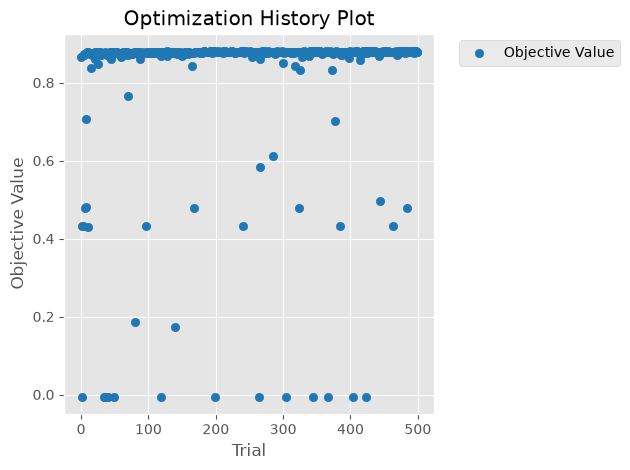

In [166]:
import optuna

def objective(trial):
    Model=trial.suggest_categorical('Model',['RF','XGB'])
    if Model=='RF':
        params={
        'max_depth':trial.suggest_int('max_depth',2,30),
        'max_leaf_nodes':trial.suggest_int('max_leaf_nodes',2,30),
        'n_estimators':trial.suggest_int('n_estimators',100,2000),
        'min_samples_split':trial.suggest_int('min_samples_split',2,400),
        'bootstrap':trial.suggest_categorical('bootstrap',[False,True]),
        'min_impurity_decrease':trial.suggest_float('min_impurity_decrease',0.0001,0.3) 
        }
        Model=Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', RandomForestRegressor(**params,random_state=42))
        ])
    else:
        params = {
        "objective": "reg:squarederror",
        "eval_metric": "rmse",
        "tree_method": "hist",
        "random_state": 42,
        "n_estimators": trial.suggest_int("n_estimators", 100, 1500, step=50),
        "learning_rate": trial.suggest_float(
            "learning_rate", 0.005, 0.3, log=True
        ),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 20),
        "gamma": trial.suggest_float("gamma", 1e-8, 5.0, log=True),
        "alpha": trial.suggest_float("alpha", 1e-8, 10.0, log=True),
        "lambda": trial.suggest_float("lambda", 1e-8, 10.0, log=True),
        }
        Model=Pipeline([
                ('preprocessor', preprocessor),
                ('regressor', xgb.XGBRegressor(**params))
        ])

    Score=cross_val_score(estimator=Model,X=X,y=y_transformed,cv=10,n_jobs=-1,scoring='r2')

    return Score.mean()

study=optuna.create_study(direction='maximize',sampler=optuna.samplers.TPESampler())
study.optimize(objective,n_trials=500,show_progress_bar=True)
optuna.logging.set_verbosity(optuna.logging.WARNING)
display(optuna.visualization.matplotlib.plot_optimization_history(study=study,target=lambda x : x.values[0]))


In [168]:
study.best_trial

FrozenTrial(number=429, state=<TrialState.COMPLETE: 1>, values=[0.8817400877513821], datetime_start=datetime.datetime(2026, 10, 9, 3, 34, 25, 490936), datetime_complete=datetime.datetime(2026, 10, 9, 3, 34, 27, 598587), params={'Model': 'XGB', 'n_estimators': 1250, 'learning_rate': 0.0050335949030557115, 'max_depth': 8, 'subsample': 0.6084773967665432, 'colsample_bytree': 0.822509366455276, 'min_child_weight': 1, 'gamma': 3.2576597903720334e-07, 'alpha': 0.21463815668626066, 'lambda': 0.002929878382654817}, user_attrs={}, system_attrs={}, intermediate_values={}, distributions={'Model': CategoricalDistribution(choices=('RF', 'XGB')), 'n_estimators': IntDistribution(high=1500, log=False, low=100, step=50), 'learning_rate': FloatDistribution(high=0.3, log=True, low=0.005, step=None), 'max_depth': IntDistribution(high=12, log=False, low=3, step=1), 'subsample': FloatDistribution(high=1.0, log=False, low=0.5, step=None), 'colsample_bytree': FloatDistribution(high=1.0, log=False, low=0.5, st

In [176]:
params={'n_estimators': 1250,
 'learning_rate': 0.0050335949030557115,
 'max_depth': 8,
 'subsample': 0.6084773967665432,
 'colsample_bytree': 0.822509366455276,
 'min_child_weight': 1,
 'gamma': 3.2576597903720334e-07,
 'alpha': 0.21463815668626066,
 'lambda': 0.002929878382654817}

final_model=Pipeline([
                ('preprocessor', preprocessor),
                ('regressor', xgb.XGBRegressor(**params,random_state=42))
        ])
score=cross_val_score(estimator=final_model,X=X,y=y_transformed,scoring='r2',cv=10)
score.mean()

np.float64(0.8812767949903378)

In [177]:
final_model.fit(X,y_transformed)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['property_type','sector','bedRoom',...,'Servant Room','furnishstatus', 'built_up_area']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed throu

### Exporting the model

In [174]:
import pickle

with open('pipeline.pkl', 'wb') as file:
    pickle.dump(final_model, file)

In [137]:
with open('df.pkl', 'wb') as file:
    pickle.dump(X, file)